# Exercise 7 — Bring your own target

*Covers notebooks all. Difficulty: open*

Your science, the WCC, and Jupyter AI as a pair programmer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

This exercise has no solution key beyond a worked example. Work with Jupyter AI as a pair
programmer: you supply the astronomy, it supplies the code, you check the numbers.

### 7.1 — Pick a target

Your own, or one from the reflected-light sample of the ESC notebooks (they are
bright: V = 4 to 6; the file is `lazuli/data/12_nearby_rv_giants.csv`). Write down: the spectral type or SED, the magnitude and the system it is in, and
the measurement you want (a detection? a precision per hour? a depth?).

In [3]:
import pandas as pd
from pathlib import Path
csv = Path("../../../../esc/tutorial/data/12_nearby_rv_giants.csv")
targets = pd.read_csv(csv)
targets

,pl_name,hostname,pl_orbsmax,pl_orbeccen,pl_bmassj,pl_bmassprov,pl_radj,sy_dist,sy_vmag,st_spectype
0,55 Cnc d,55 Cnc,5.60000,0.0913,3.878000,Mass,1.16,12.58550,5.95084,G8 V
1,HD 10647 b,HD 10647,2.01500,0.1500,0.940000,Msini,1.23,17.33570,5.52000,F9 V
2,HD 62509 b,HD 62509,1.64000,0.0200,2.300000,Msini,1.19,10.34000,1.12512,K0IIIvar
3,HD 160691 b,HD 160691,1.50000,0.0505,4.300000,Mass,NaN,15.59810,5.12000,G3 IV-V
4,7 CMa b,7 CMa,1.75800,0.0600,1.850000,Msin(i)/sin(i),1.20,19.81010,3.95000,K1III(+M)
5,HD 190360 b,HD 190360,3.96500,0.3342,1.689591,Mass,1.20,16.00690,5.73800,G7 IV-V
6,14 Her b,14 Her,2.83900,0.3683,8.900000,Mass,1.12,17.93230,6.61935,K0
7,47 UMa b,47 UMa,2.10000,0.0320,2.530000,Msini,1.18,13.79670,5.03352,G0V
8,HD 147513 b,HD 147513,1.32000,0.2600,1.210000,Msini,1.22,12.90320,5.37000,G3/5V
9,HD 39091 b,HD 39091,3.28000,0.6420,14.100000,Mass,1.10,18.27020,5.65000,G0 V


### 7.2 — Describe it to the agent

A prompt that works: *"I want to observe `<target>` (`<spectral type>`, V = `<mag>` Vega) with the
WCC in the r band. Using wcc_etc, build the scene with get_scene with an explicit bandpass and
magsys, find the smallest read split that avoids saturation at 60 s with Simulation.from_sensorfilter
for 'zwo:r' and 'zwo:r+1', and report the precision per point in ppm."*

Check what it does against notebooks 02 and 04: does it pass `warn=False` and look at `saturated`?
Does it respect the 0.25 s minimum frame time?

In [4]:
READS = (1, 2, 3, 6, 10, 30, 60, 120, 240)

def choose_reads(sim, t, reads=READS, **kw):
    """Smallest read count whose per-frame image has no saturated pixel; (None, last result) if none works."""
    for n in reads:
        r = sim.get_image_snr(t, n_reads=n, warn=False, **kw)
        if not np.any(r["saturated"]):
            return n, r
    return None, r

# Worked example: HD 27442 (K1/2 III, V = 4.44). Nearest Pickles template: K3III.
scene = get_scene("K3III", mag=4.44, bandpass="johnson_v", magsys="vegamag")
for label in ("zwo:r", "zwo:r+1", "zwo:bb2"):
    sim = Simulation.from_sensorfilter(label, scene)
    peak = sim.get_peak_pixel(0.25, units="e-").value
    print(f"{label:8s}: peak pixel in a 0.25 s frame {peak:9.0f} e- = {peak / sim.sensor.meta['well_depth']:5.0f} x the well depth")
# WCC cannot observe a V = 4.4 star unsaturated in any mode: the ESC or the IFS are the instruments for this sample.
# How faint would it have to be? Sweep the magnitude in the most forgiving mode:
sim = Simulation.from_sensorfilter("zwo:bb2", scene)
for m in (6, 7, 8, 9, 10):
    sim.update(source__mag=float(m))
    n, r = choose_reads(sim, 60)
    print(f"V = {m}: " + (f"{n} x {60 / n:.2f} s, {1e6 / r['snr']:.0f} ppm per 60 s" if n else "saturated at every split"))

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


zwo:r   : peak pixel in a 0.25 s frame  21499571 e- =  1321 x the well depth
zwo:r+1 : peak pixel in a 0.25 s frame    413138 e- =    25 x the well depth
zwo:bb2 : peak pixel in a 0.25 s frame    243517 e- =    15 x the well depth
V = 6: saturated at every split
V = 7: saturated at every split
V = 8: 240 x 0.25 s, 15 ppm per 60 s
V = 9: 60 x 1.00 s, 23 ppm per 60 s
V = 10: 30 x 2.00 s, 37 ppm per 60 s


### 7.3 — One plot, one number

Whatever your target: produce the one plot that answers your question (SNR versus time, precision
versus magnitude, depth versus filter, a simulated light curve or image) and the one number you would
put in a proposal.

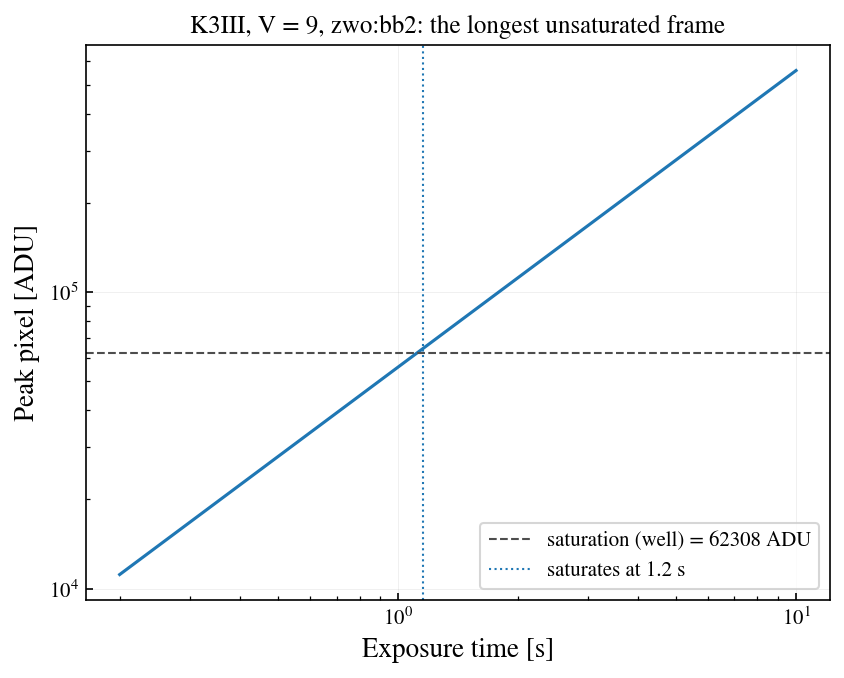

In [5]:
sim = Simulation.from_sensorfilter("zwo:bb2", get_scene("K3III", mag=9, bandpass="johnson_v", magsys="vegamag"))
fig, ax = sim.plot_peak_pixel(np.logspace(-0.7, 1, 50))
ax.set(xscale="log", yscale="log", title="K3III, V = 9, zwo:bb2: the longest unsaturated frame")
plt.show()

### 7.4 — What was wrong

Ask the agent to list every assumption it made that you did not state (template, magnitude system,
background, aperture, jitter, no overheads). Which ones would change the answer by more than a factor
of two?

> 🤖 **Ask Jupyter AI:** *List every assumption you made in 7.2 that I did not state, and for each one estimate how much the precision would change if it were wrong.*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/wcc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*